| **Inicio**         | **atrás 1**                          | **Siguiente 3**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./3_1_Probabilidad.ipynb) | [⏩](./3_3_Estadistica.ipynb) |

# 1. Mapa general de las distribuciones

Primero ubícalas:

```text
DISTRIBUCIONES
│
├── DISCRETAS
│   │
│   ├── Bernoulli
│   │       └── Un solo experimento
│   │
│   ├── Binomial
│   │       └── n experimentos Bernoulli
│   │
│   └── Poisson
│           └── Número de eventos en un intervalo
│
└── CONTINUAS
    │
    ├── Uniforme
    │       └── Todos los valores igualmente plausibles
    │
    ├── Normal
    │       └── Ruido / errores / fenómenos agregados
    │
    ├── Exponencial
    │       └── Tiempo de espera
    │
    └── Gamma
            └── Tiempo hasta varios eventos
```

Una distinción fundamental:

### Discreta

La variable puede tomar valores como:

$$
0,1,2,3,\ldots
$$

y usamos una **PMF**:

$$
P(X=k).
$$

### Continua

La variable puede tomar cualquier valor de un intervalo:

$$
X\in\mathbb R.
$$

Usamos una **PDF**:

$$
f_X(x).
$$

En una continua:

$$
P(X=x)=0.
$$

Las probabilidades se obtienen mediante áreas:

$$
P(a<X<b)=\int_a^b f_X(x)\,dx.
$$

# 2. BERNOULLI

La distribución Bernoulli es la más básica de las siete.

Representa **un único experimento que solamente tiene dos resultados**.

Por ejemplo:

$$
X=
\begin{cases}
1 & \text{éxito}\\
0 & \text{fracaso}
\end{cases}
$$

con:

$$
P(X=1)=p
$$

y:

$$
P(X=0)=1-p.
$$

Escribimos:

$$
\boxed{X\sim Bernoulli(p)}
$$

## 2.1 Función de probabilidad

Podemos escribir ambas probabilidades mediante una sola expresión:

$$
\boxed{
P(X=x)=p^x(1-p)^{1-x}
}
$$

para:

$$
x\in\{0,1\}.
$$

Compruébalo.

Si:

$$
x=1
$$

tenemos:

$$
p^1(1-p)^0=p.
$$

Si:

$$
x=0
$$

tenemos:

$$
p^0(1-p)^1=1-p.
$$

# 2.2 Esperanza

La esperanza:

$$
E[X]
=
0(1-p)+1(p)
$$

por tanto:

$$
\boxed{E[X]=p}
$$

# 2.3 Varianza

Tenemos:

$$
E[X^2]=p
$$

porque:

$$
0^2=0,\qquad1^2=1.
$$

Entonces:

$$
Var(X)=E[X^2]-E[X]^2
$$

y:

$$
\boxed{
Var(X)=p(1-p)
}
$$

# 2.4 Ejemplo real: sensor defectuoso

Supongamos que un sensor tiene:

$$
p=0.03
$$

de probabilidad de fallar una medición.

Definimos:

$$
X=
\begin{cases}
1&\text{sensor falla}\\
0&\text{sensor funciona}
\end{cases}
$$

Entonces:

$$
X\sim Bernoulli(0.03).
$$

La probabilidad de fallo:

$$
P(X=1)=0.03.
$$

La esperanza:

$$
E[X]=0.03.
$$

La varianza:

$$
Var(X)=0.03(0.97)=0.0291.
$$

# 2.5 Gráfico Python

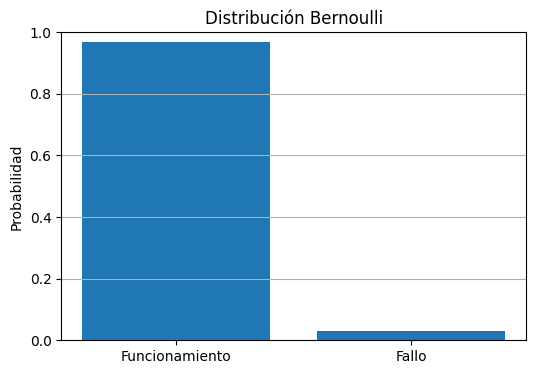

In [1]:
import numpy as np
import matplotlib.pyplot as plt

p = 0.03

x = np.array([0, 1])
prob = np.array([1-p, p])

plt.figure(figsize=(6, 4))

plt.bar(x, prob)

plt.xticks([0, 1], ["Funcionamiento", "Fallo"])
plt.ylabel("Probabilidad")
plt.title("Distribución Bernoulli")
plt.ylim(0, 1)

plt.grid(axis="y")
plt.show()

# 2.6 ¿Dónde aparece en SciML?

Bernoulli aparece cuando modelas:

* detección sí/no,
* fallo/no fallo,
* evento/no evento,
* clasificación binaria,
* activación/no activación,
* presencia/ausencia de un fenómeno.

En Machine Learning aparece directamente en:

$$
P(Y=1|X).
$$

Por ejemplo, regresión logística.

# 3. BINOMIAL

Ahora hacemos:

> muchos experimentos Bernoulli independientes.

Si:

$$
X_1,\ldots,X_n
$$

son Bernoulli con probabilidad $(p)$, entonces:

$$
X=X_1+\cdots+X_n
$$

sigue una distribución binomial:

$$
\boxed{
X\sim Binomial(n,p)
}
$$

# 3.1 Fórmula

La probabilidad de obtener exactamente $(k)$ éxitos es:

$$
\boxed{
P(X=k)=
{n\choose k}
p^k(1-p)^{n-k}
}
$$

donde:

$$
{n\choose k}
=
\frac{n!}{k!(n-k)!}.
$$

# 3.2 ¿De dónde sale?

Imagina:

$$
n=5
$$

y quieres exactamente:

$$
k=2
$$

éxitos.

Una secuencia podría ser:

```text
Éxito Éxito Fallo Fallo Fallo
```

Su probabilidad:

$$
p^2(1-p)^3.
$$

Pero existen varias formas de colocar los dos éxitos.

El número de posibilidades es:

$$
{5\choose2}=10.
$$

Por eso:

$$
P(X=2)
=
{5\choose2}p^2(1-p)^3.
$$

# 3.3 Media y varianza

Para:

$$
X\sim Binomial(n,p)
$$

tenemos:

$$
\boxed{E[X]=np}
$$

y:

$$
\boxed{Var(X)=np(1-p)}
$$

# 3.4 Ejemplo científico difícil

Supongamos que un experimento tiene:

$$
p=0.02
$$

de probabilidad de producir una medición defectuosa.

Realizamos:

$$
n=1000
$$

mediciones.

Entonces:

$$
X\sim Binomial(1000,0.02).
$$

La cantidad esperada de errores:

$$
E[X]=1000(0.02)=20.
$$

La desviación estándar:

$$
\sigma
=
\sqrt{1000(0.02)(0.98)}
$$

aproximadamente:

$$
4.43.
$$

Pregunta:

> ¿Cuál es la probabilidad de obtener 30 o más errores?

$$
P(X\ge30).
$$

Esto ya no es una probabilidad elemental.

En Python:

In [2]:
from scipy.stats import binom

n = 1000
p = 0.02

prob = binom.sf(29, n, p)

print(prob)

0.020696518673239326



Usamos `sf` porque:

$$
P(X\ge30)=1-P(X\le29).
$$

`sf` suele ser numéricamente más estable que calcular directamente `1-cdf`.

# 3.5 Gráfico

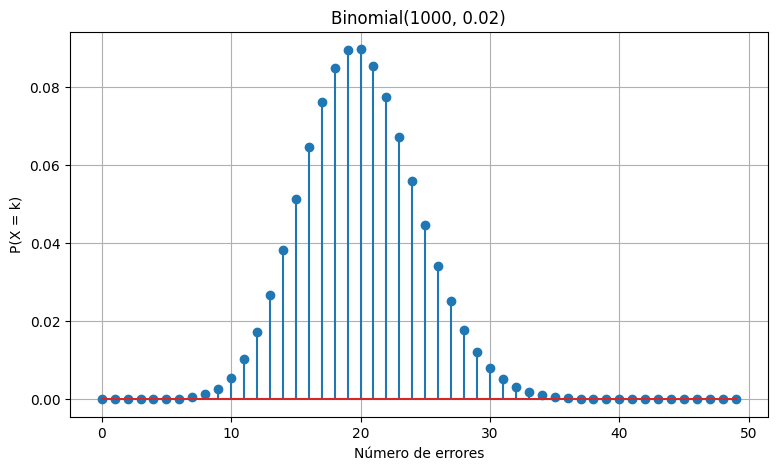

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

n = 1000
p = 0.02

x = np.arange(0, 50)

pmf = binom.pmf(x, n, p)

plt.figure(figsize=(9, 5))

plt.stem(x, pmf)

plt.xlabel("Número de errores")
plt.ylabel("P(X = k)")
plt.title("Binomial(1000, 0.02)")
plt.grid()

plt.show()

# 3.6 Aplicación diaria

La binomial aparece en:

* número de productos defectuosos,
* número de clientes que compran,
* número de respuestas correctas,
* número de sensores que fallan,
* número de pacientes que responden a un tratamiento,
* número de paquetes que llegan tarde.

# 4. POISSON

La Poisson responde una pregunta diferente:

> **¿Cuántos eventos ocurren durante un intervalo?**

Por ejemplo:

* llamadas por hora,
* accidentes por día,
* defectos por metro de material,
* partículas detectadas por segundo,
* solicitudes a un servidor,
* terremotos por año.

Escribimos:

$$
\boxed{
X\sim Poisson(\lambda)
}
$$

donde $(\lambda)$ es la tasa media de eventos en el intervalo.

# 4.1 Fórmula

$$
\boxed{
P(X=k)
=
\frac{e^{-\lambda}\lambda^k}{k!}
}
$$

para:

$$
k=0,1,2,\ldots
$$

# 4.2 Media y varianza

Una característica importantísima:

$$
\boxed{
E[X]=\lambda
}
$$

y:

$$
\boxed{
Var(X)=\lambda
}
$$

Por tanto:

$$
\sigma=\sqrt{\lambda}.
$$

# 4.3 Ejemplo real

Un servidor recibe en promedio:

$$
\lambda=50
$$

peticiones por segundo.

Entonces:

$$
X\sim Poisson(50).
$$

La probabilidad de recibir exactamente 60:

$$
P(X=60)
=
\frac{e^{-50}50^{60}}{60!}.
$$

Python:

In [4]:
from scipy.stats import poisson

lam = 50

prob = poisson.pmf(60, lam)

print(prob)

0.020104872145675377


# 4.4 Gráfico

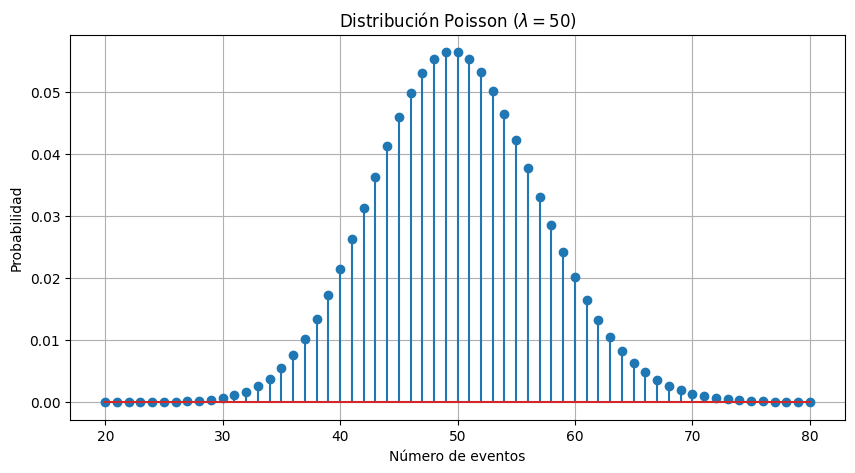

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import poisson

lam = 50

x = np.arange(20, 81)

pmf = poisson.pmf(x, lam)

plt.figure(figsize=(10, 5))

plt.stem(x, pmf)

plt.xlabel("Número de eventos")
plt.ylabel("Probabilidad")
plt.title(r"Distribución Poisson ($\lambda=50$)")
plt.grid()

plt.show()

# 4.5 Aplicación científica: detección de partículas

Supón que un detector registra partículas.

La tasa media es:

$$
\lambda=100
$$

partículas por segundo.

Entonces:

$$
N(t)\sim Poisson(100t)
$$

para un intervalo de duración $(t)$.

Esto es fundamental en:

* física experimental,
* astronomía,
* detección de radiación,
* biología,
* telecomunicaciones.

# 4.6 Relación Binomial → Poisson

Una conexión muy importante.

Si:

$$
X\sim Binomial(n,p)
$$

y hacemos:

$$
n\rightarrow\infty
$$

$$
p\rightarrow0
$$

manteniendo:

$$
np=\lambda,
$$

entonces:

$$
\boxed{
Binomial(n,p)
\approx
Poisson(\lambda)
}
$$

Esto tiene una interpretación física:

> muchos ensayos, cada uno con probabilidad muy pequeña de que ocurra un evento.

# 5. UNIFORME

Ahora pasamos a continuas.

La distribución uniforme dice:

> todos los valores de un intervalo tienen la misma densidad.

Escribimos:

$$
\boxed{
X\sim U(a,b)
}
$$

# 5.1 Densidad

$$
f_X(x)=
\begin{cases}
\dfrac1{b-a},&a\le x\le b\\
0,&\text{en otro caso}.
\end{cases}
$$

# 5.2 ¿Por qué la altura es $(1/(b-a))$?

La probabilidad total debe ser:

$$
1.
$$

El área bajo la densidad es:

$$
\int_a^b\frac1{b-a}dx
$$

$$
=
\frac{b-a}{b-a}=1.
$$

# 5.3 Ejemplo real

Supongamos que un autobús llega aleatoriamente entre:

$$
10:00
$$

y:

$$
10:20.
$$

Si suponemos que cualquier instante es igualmente probable:

$$
X\sim U(0,20)
$$

donde $(X)$ representa minutos después de las 10:00.

La probabilidad de esperar menos de 5 minutos:

$$
P(X<5)=\frac5{20}=0.25.
$$

# 5.4 Ejemplo científico

Supongamos que un parámetro físico solamente sabemos que está entre:

$$
2.0\le\theta\le3.0
$$

y no tenemos información adicional.

Podemos usar:

$$
\theta\sim U(2,3).
$$

Esto puede representar un **prior no informativo simple**.

# 5.5 Python

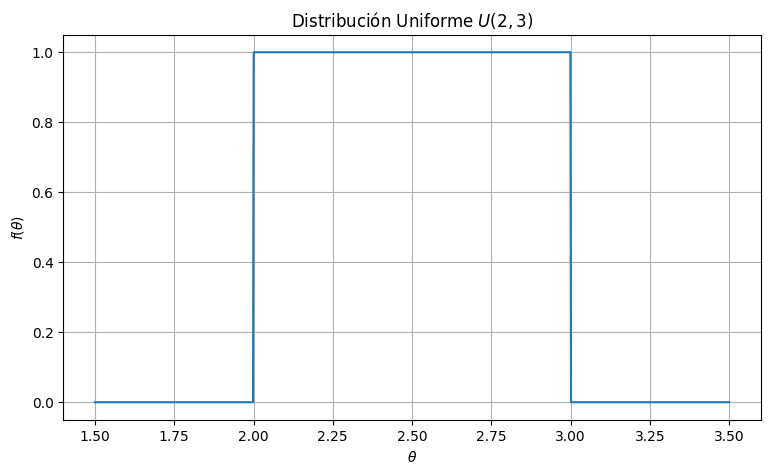

In [6]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import uniform

a = 2
b = 3

x = np.linspace(1.5, 3.5, 1000)

pdf = uniform.pdf(x, loc=a, scale=b-a)

plt.figure(figsize=(9, 5))

plt.plot(x, pdf)

plt.xlabel(r"$\theta$")
plt.ylabel(r"$f(\theta)$")
plt.title(r"Distribución Uniforme $U(2,3)$")
plt.grid()

plt.show()

# 6. NORMAL

Ahora llegamos a una de las distribuciones más importantes de toda la ciencia.

$$
\boxed{
X\sim N(\mu,\sigma^2)
}
$$

# 6.1 Densidad

$$
\boxed{
f(x)
=
\frac1{\sigma\sqrt{2\pi}}
\exp
\left[
-\frac{(x-\mu)^2}{2\sigma^2}
\right]
}
$$

donde:

* $(\mu)$ = media,
* $(\sigma)$ = desviación estándar,
* $(\sigma^2)$ = varianza.

# 6.2 Interpretación

$(\mu)$ mueve la distribución:

$$
\mu\uparrow
$$

→ la curva se desplaza a la derecha.

$(\sigma)$ controla la dispersión:

$$
\sigma\uparrow
$$

→ curva más ancha.

# 6.3 Regla 68-95-99.7

Para una normal:

$$
P(\mu-\sigma<X<\mu+\sigma)
\approx68.27\%.
$$

Dentro de:

$$
\mu\pm2\sigma
$$

aproximadamente:

$$
95.45\%.
$$

Dentro de:

$$
\mu\pm3\sigma
$$

aproximadamente:

$$
99.73\%.
$$

# 6.4 Ejemplo real: error de sensor

Supongamos:

$$
T_{\text{real}}=100^\circ C.
$$

El sensor tiene:

$$
\sigma=2^\circ C.
$$

Modelamos:

$$
T_{\text{medido}}
\sim N(100,2^2).
$$

Pregunta:

> ¿Cuál es la probabilidad de que la medición esté entre 97 y 103?

Python:

In [7]:
from scipy.stats import norm

mu = 100
sigma = 2

prob = (
    norm.cdf(103, mu, sigma)
    -
    norm.cdf(97, mu, sigma)
)

print(prob)

0.8663855974622838


# 6.5 Gráfico Python

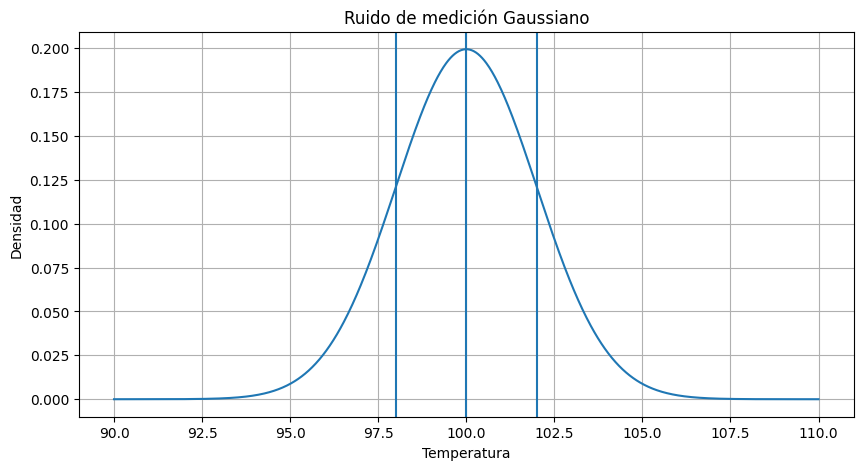

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

mu = 100
sigma = 2

x = np.linspace(90, 110, 1000)

pdf = norm.pdf(x, mu, sigma)

plt.figure(figsize=(10, 5))

plt.plot(x, pdf)

plt.axvline(mu)
plt.axvline(mu - sigma)
plt.axvline(mu + sigma)

plt.xlabel("Temperatura")
plt.ylabel("Densidad")
plt.title("Ruido de medición Gaussiano")
plt.grid()

plt.show()

# 6.6 ¿Por qué aparece tanto la Normal?

Aquí entra el **Teorema Central del Límite**.

Si una variable es la suma de muchos pequeños efectos aproximadamente independientes:

$$
X=X_1+\cdots+X_n,
$$

bajo condiciones bastante generales:

$$
\frac{X-\mu}{\sigma}
$$

tiende hacia:

$$
N(0,1).
$$

Por eso los errores experimentales frecuentemente se aproximan mediante una normal.

# 6.7 SciML

Un modelo científico típico puede ser:

$$
\boxed{
y=f(x,\theta)+\epsilon
}
$$

con:

$$
\epsilon\sim N(0,\sigma^2).
$$

Entonces:

$$
y|x,\theta
\sim
N(f(x,\theta),\sigma^2).
$$

Esto permite construir una **likelihood**:

$$
p(y|\theta).
$$

Y después hacer inferencia sobre:

$$
\theta.
$$

# 7. EXPONENCIAL

La distribución exponencial modela principalmente:

> **tiempo de espera hasta el próximo evento.**

Escribimos:

$$
\boxed{
X\sim Exponential(\lambda)
}
$$

donde:

$$
\lambda>0
$$

es la tasa.

# 7.1 Densidad

$$
\boxed{
f(x)=\lambda e^{-\lambda x}
}
$$

para:

$$
x\ge0.
$$


# 7.2 Función de distribución


$$
F(x)=P(X\le x).
$$

Integrando:

$$
F(x)
=
\int_0^x\lambda e^{-\lambda t}dt.
$$

Obtenemos:

$$
\boxed{
F(x)=1-e^{-\lambda x}
}
$$

# 7.3 Función de supervivencia

Muy importante:

$$
P(X>x)
$$

es:

$$
\boxed{
P(X>x)=e^{-\lambda x}
}
$$

# 7.4 Media y varianza

$$
\boxed{
E[X]=\frac1\lambda
}
$$

y:

$$
\boxed{
Var(X)=\frac1{\lambda^2}
}
$$

# 7.5 Ejemplo real

Un servidor recibe solicitudes con tasa:

$$
\lambda=2
$$

solicitudes por segundo.

El tiempo entre solicitudes puede modelarse como:

$$
X\sim Exponential(2).
$$

El tiempo medio de espera:

$$
E[X]=\frac12=0.5\text{ s}.
$$

# 7.6 Probabilidad de esperar más de un segundo

$$
P(X>1)=e^{-2}.
$$

Por tanto:

$$
P(X>1)\approx0.1353.
$$

Python:

In [9]:
import numpy as np

lam = 2

prob = np.exp(-lam * 1)

print(prob)

0.1353352832366127


# 7.7 Gráfico

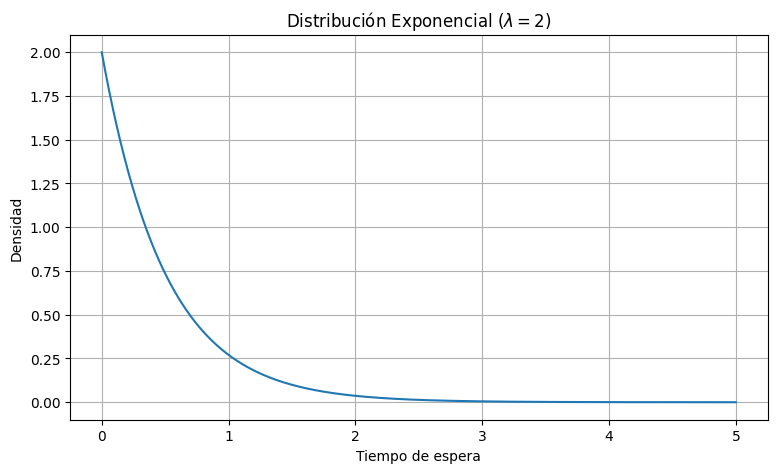

In [10]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import expon

lam = 2

x = np.linspace(0, 5, 1000)

pdf = expon.pdf(x, scale=1/lam)

plt.figure(figsize=(9, 5))

plt.plot(x, pdf)

plt.xlabel("Tiempo de espera")
plt.ylabel("Densidad")
plt.title(r"Distribución Exponencial ($\lambda=2$)")
plt.grid()

plt.show()

# 7.8 Una propiedad sorprendente

La exponencial es **memoryless**:

$$
\boxed{
P(X>s+t|X>s)=P(X>t)
}
$$

Interpretación:

> si ya llevas esperando 10 minutos, el modelo exponencial no "recuerda" esos 10 minutos.

Esto es importante en procesos de llegada.

# 8. GAMMA

Gamma es una distribución especialmente importante porque generaliza la idea de exponencial.

Si Exponencial representa:

> tiempo hasta el primer evento,

Gamma puede representar:

> tiempo hasta varios eventos.

# 8.1 Parámetros

Usaremos:

$$
\boxed{
X\sim Gamma(\alpha,\theta)
}
$$

donde:

* $(\alpha)$ = shape,
* $(\theta)$ = scale.

Su densidad:

$$
\boxed{
f(x)=
\frac1{\Gamma(\alpha)\theta^\alpha}
x^{\alpha-1}e^{-x/\theta}
}
$$

para:

$$
x>0.
$$

Aquí:

$$
\Gamma(\alpha)
$$

es la función Gamma.

# 8.2 Media

$$
\boxed{
E[X]=\alpha\theta
}
$$

# 8.3 Varianza

$$
\boxed{
Var(X)=\alpha\theta^2
}
$$

# 8.4 Relación con Exponencial

Si:

$$
\alpha=1
$$

entonces:

$$
Gamma(1,\theta)
$$

es una distribución exponencial con:

$$
\lambda=\frac1\theta.
$$

Por tanto:

$$
\boxed{
Exponential
\subset Gamma
}
$$

en cierto sentido.

# 8.5 Ejemplo científico

Supongamos que los eventos ocurren siguiendo un proceso de Poisson con tasa:

$$
\lambda=4
$$

eventos por hora.

¿Cuánto tiempo debemos esperar hasta observar el quinto evento?

El tiempo hasta el quinto evento sigue:

$$
X\sim Gamma(k=5,\text{rate}=4).
$$

Si utilizamos parámetros shape-scale:

$$
\theta=\frac14.
$$

Entonces:

$$
E[X]
=
5\frac14
=
1.25\text{ horas}.
$$

Esto es extremadamente útil en:

* reliability,
* colas,
* procesos de llegada,
* supervivencia,
* física,
* biología.

# 8.6 Python

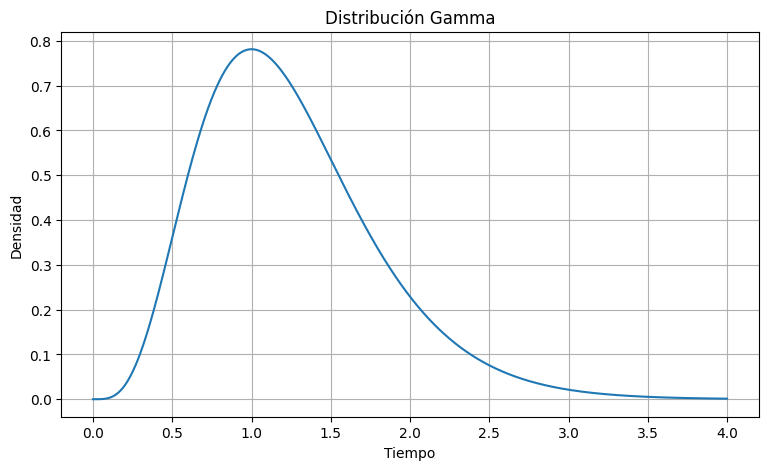

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma

alpha = 5
theta = 1/4

x = np.linspace(0, 4, 1000)

pdf = gamma.pdf(x, a=alpha, scale=theta)

plt.figure(figsize=(9, 5))

plt.plot(x, pdf)

plt.xlabel("Tiempo")
plt.ylabel("Densidad")
plt.title("Distribución Gamma")
plt.grid()

plt.show()

# 8.7 Gamma con diferentes formas

Aquí puedes ver por qué el parámetro $(\alpha)$ es importante:

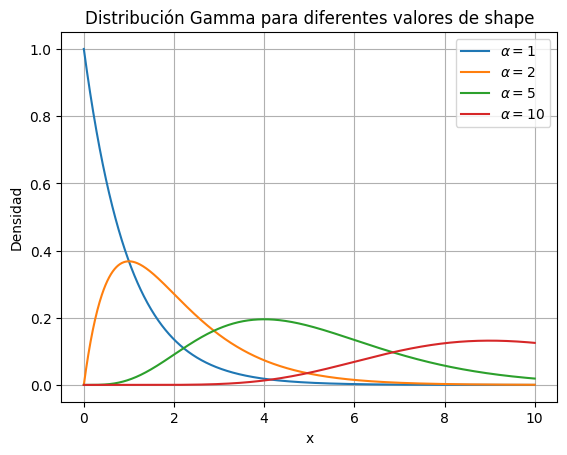

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma

x = np.linspace(0, 10, 1000)

for alpha in [1, 2, 5, 10]:
    pdf = gamma.pdf(x, a=alpha, scale=1)
    plt.plot(x, pdf, label=fr"$\alpha={alpha}$")

plt.xlabel("x")
plt.ylabel("Densidad")
plt.title("Distribución Gamma para diferentes valores de shape")
plt.legend()
plt.grid()

plt.show()

Cuando:

$$
\alpha=1
$$

obtenemos la exponencial.

Cuando $(\alpha)$ aumenta, la distribución se vuelve más concentrada alrededor de su media.

# 9. RELACIÓN ENTRE LAS DISTRIBUCIONES

Esta parte quiero que la estudies especialmente.

No son siete distribuciones aisladas.

Existe una estructura.

## Bernoulli

Un experimento:

$$
\boxed{
X\in\{0,1\}
}
$$

## Binomial

Suma de Bernoulli:

$$
\boxed{
X=X_1+\cdots+X_n
}
$$

## Poisson

Número de eventos en un intervalo.

## Exponencial

Tiempo hasta el primer evento de un proceso de Poisson.

## Gamma

Tiempo hasta el $(k)$-ésimo evento.

# 10. La cadena Poisson → Exponencial → Gamma

Esta conexión es particularmente importante.

Supongamos:

$$
N(t)\sim Poisson(\lambda t).
$$

Entonces:

### Número de eventos

$$
N(t)
$$

### Tiempo hasta primer evento

$$
T_1\sim Exponential(\lambda)
$$

### Tiempo hasta segundo evento

$$
T_2\sim Gamma(2,\lambda)
$$

### Tiempo hasta $(k)$-ésimo evento

$$
T_k\sim Gamma(k,\lambda)
$$

Es decir:

```text
PROCESO DE POISSON
       │
       ├── ¿Cuántos eventos?
       │       ↓
       │    Poisson
       │
       └── ¿Cuánto tiempo?
               │
               ├── primer evento
               │       ↓
               │   Exponencial
               │
               └── k-ésimo evento
                       ↓
                     Gamma
```

# 11. Relación Binomial → Poisson

También tienes:

$$
Binomial(n,p)
$$

que en ciertos casos puede aproximarse por:

$$
Poisson(\lambda)
$$

con:

$$
\lambda=np.
$$

Entonces tienes otra cadena:

```text
Bernoulli
   │
   │ sumar n experimentos
   ▼
Binomial
   │
   │ n grande, p pequeño
   ▼
Poisson
```

# 12. Una comparación importante

| Distribución | Tipo     | Pregunta                                   |
| ------------ | -------- | ------------------------------------------ |
| Bernoulli    | Discreta | ¿Éxito o fracaso?                          |
| Binomial     | Discreta | ¿Cuántos éxitos en $(n)$ intentos?         |
| Poisson      | Discreta | ¿Cuántos eventos ocurren?                  |
| Uniforme     | Continua | ¿Valor desconocido dentro de un intervalo? |
| Normal       | Continua | ¿Ruido/errores alrededor de una media?     |
| Exponencial  | Continua | ¿Cuánto hasta el próximo evento?           |
| Gamma        | Continua | ¿Cuánto hasta varios eventos?              |

# 13. Algo MUY importante para SciML: simular

Una distribución no solamente sirve para calcular:

$$
P(X=x).
$$

También podemos **generar muestras**.

Por ejemplo:

In [13]:
import numpy as np

np.random.seed(42)

samples = np.random.normal(
    loc=0,
    scale=1,
    size=10000
)

Tenemos:

$$
X_1,X_2,\ldots,X_{10000}.
$$

Entonces podemos aproximar:

$$
E[X]
$$

mediante:

$$
\boxed{
\hat E[X]
=
\frac1N\sum_{i=1}^NX_i
}
$$

Esto es Monte Carlo.

# 14. Ejemplo Monte Carlo: Normal

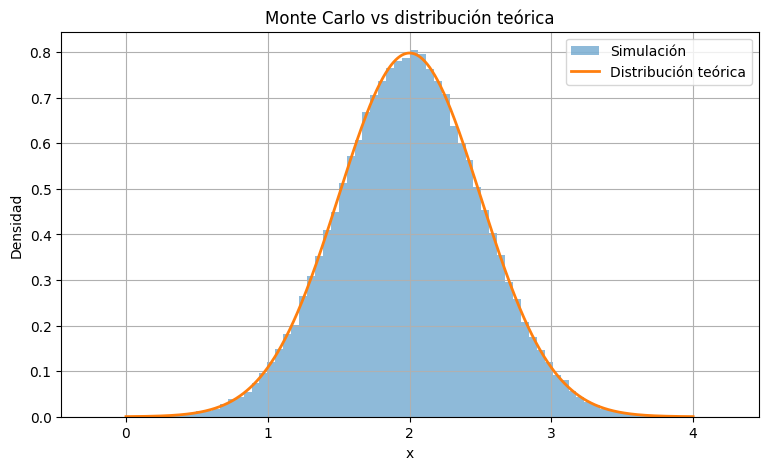

In [14]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

np.random.seed(42)

N = 100000

samples = np.random.normal(
    loc=2,
    scale=0.5,
    size=N
)

x = np.linspace(0, 4, 1000)

theoretical = norm.pdf(x, 2, 0.5)

plt.figure(figsize=(9, 5))

plt.hist(
    samples,
    bins=80,
    density=True,
    alpha=0.5,
    label="Simulación"
)

plt.plot(
    x,
    theoretical,
    linewidth=2,
    label="Distribución teórica"
)

plt.xlabel("x")
plt.ylabel("Densidad")
plt.title("Monte Carlo vs distribución teórica")
plt.legend()
plt.grid()

plt.show()

La idea es:

$$
\boxed{
\text{Distribución teórica}
\approx
\text{histograma de muchas muestras}
}
$$

cuando $(N)$ es suficientemente grande.

# 15. Esto es exactamente lo que usarás en SciML

Supongamos:

$$
\theta\sim Gamma(\alpha,\theta).
$$

Tienes una ecuación física:

$$
\frac{du}{dt}
=
F(u,\theta).
$$

No haces una sola simulación.

Haces:

$$
\theta_1,\theta_2,\ldots,\theta_N.
$$

Y resuelves:

$$
u_1(t),u_2(t),\ldots,u_N(t).
$$

Entonces puedes calcular:

$$
E[u(t)]
$$

$$
Var(u(t))
$$

y:

$$
P(u(t)>u_{\text{critical}}).
$$

Esto se llama:

$$
\boxed{\text{Uncertainty Quantification (UQ)}}
$$

y es una conexión directa entre **probabilidad + métodos numéricos + SciML**.

# 16. Ejemplo conceptual completo de SciML

Supongamos:

$$
\frac{du}{dt}=-\theta u
$$

con:

$$
u(0)=1.
$$

La solución exacta:

$$
u(t)=e^{-\theta t}.
$$

Pero no conocemos exactamente $(\theta)$.

Supongamos:

$$
\theta\sim Gamma(5,0.2).
$$

Entonces cada simulación tiene un valor distinto:

$$
\theta_1,\theta_2,\ldots,\theta_N.
$$

Y por tanto:

$$
u_i(t)=e^{-\theta_i t}.
$$

# 17. Simulación Python

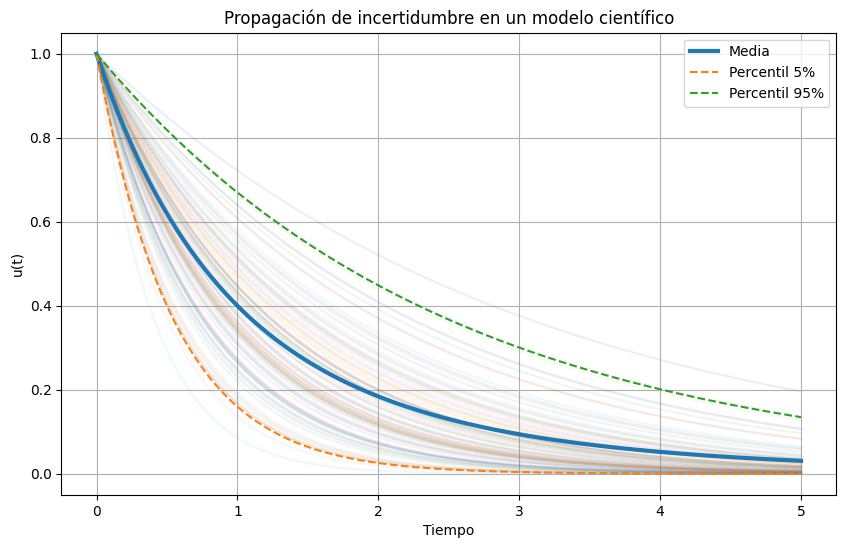

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import gamma

np.random.seed(42)

N = 5000

alpha = 5
theta_scale = 0.2

theta_samples = gamma.rvs(
    a=alpha,
    scale=theta_scale,
    size=N
)

t = np.linspace(0, 5, 300)

solutions = np.exp(
    -theta_samples[:, None] * t[None, :]
)

mean_solution = np.mean(solutions, axis=0)

lower = np.percentile(solutions, 5, axis=0)
upper = np.percentile(solutions, 95, axis=0)

plt.figure(figsize=(10, 6))

for i in range(100):
    plt.plot(t, solutions[i], alpha=0.08)

plt.plot(
    t,
    mean_solution,
    linewidth=3,
    label="Media"
)

plt.plot(
    t,
    lower,
    linestyle="--",
    label="Percentil 5%"
)

plt.plot(
    t,
    upper,
    linestyle="--",
    label="Percentil 95%"
)

plt.xlabel("Tiempo")
plt.ylabel("u(t)")
plt.title("Propagación de incertidumbre en un modelo científico")
plt.legend()
plt.grid()

plt.show()

Este ejemplo es mucho más cercano a SciML que lanzar un dado.

Tienes:

$$
\boxed{
\text{Distribución}
\rightarrow
\text{parámetro incierto}
\rightarrow
\text{simulación física}
\rightarrow
\text{distribución de soluciones}
}
$$

# 18. Tu ruta después de estas 7 distribuciones



Para tu preparación de SciML, yo seguiría:

```text
DISTRIBUCIONES
│
├── Bernoulli
├── Binomial
├── Poisson
├── Uniforme
├── Normal
├── Exponencial
└── Gamma
       │
       ▼
ESPERANZA
       │
       ▼
VARIANZA
       │
       ▼
COVARIANZA
       │
       ▼
CORRELACIÓN
       │
       ▼
VARIABLES ALEATORIAS CONJUNTAS
       │
       ▼
NORMAL MULTIVARIADA
       │
       ├── Matriz de covarianza
       ├── Eigenvalues
       ├── Eigenvectors
       ├── SVD
       └── Cholesky
       │
       ▼
LEY DE LOS GRANDES NÚMEROS
       │
       ▼
TEOREMA CENTRAL DEL LÍMITE
       │
       ▼
MONTE CARLO
       │
       ▼
MÉTODOS DE MONTE CARLO
       │
       ▼
INFERENCIA
       │
       ▼
BAYES
       │
       ▼
INVERSE PROBLEMS
       │
       ▼
UNCERTAINTY QUANTIFICATION
       │
       ▼
SCIENTIFIC MACHINE LEARNING
```



| **Inicio**         | **atrás 1**                          | **Siguiente 3**                                    |
| ------------------ | ------------------------------------ | -------------------------------------------------- |
| [🏠](../README.md) | [⏪](./3_1_Probabilidad.ipynb) | [⏩](./3_3_Estadistica.ipynb) |